# Hierarchical clustering, step by step

Agglomerative (bottom-up) clustering starts with every point as its own cluster and repeatedly merges the two closest clusters until one is left. The full merge history is a **dendrogram**; cutting it at some height gives the clusters.

This notebook:
1. clusters a small toy dataset by hand-inspectable steps,
2. compares linkage methods,
3. picks the number of clusters from the dendrogram and the silhouette score,
4. applies the same workflow to the real Iris dataset.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.datasets import load_iris
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

## 1. A toy dataset
Ten points in 2-D. By eye there are two groups: a lower-left one and an upper-right one.

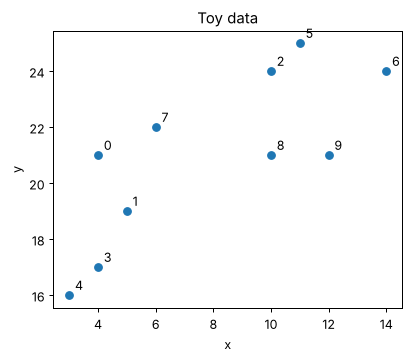

In [2]:
x = [4, 5, 10, 4, 3, 11, 14, 6, 10, 12]
y = [21, 19, 24, 17, 16, 25, 24, 22, 21, 21]
points = np.column_stack([x, y])

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(x, y)
for i, (px, py) in enumerate(points):
    ax.annotate(str(i), (px + 0.2, py + 0.2))
ax.set(title="Toy data", xlabel="x", ylabel="y")

## 2. Build the dendrogram
`linkage` returns the merge history: each row is *(cluster a, cluster b, distance, size of the new cluster)*. Ward linkage merges the pair that increases total within-cluster variance the least.

first three merges:
 [[2.   5.   1.41 2.  ]
 [3.   4.   1.41 2.  ]
 [8.   9.   2.   2.  ]]


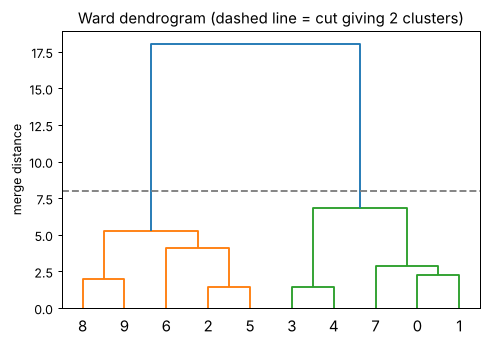

In [3]:
Z = linkage(points, method="ward")
print("first three merges:\n", Z[:3].round(2))

fig, ax = plt.subplots(figsize=(6, 4))
dendrogram(Z, ax=ax)
ax.axhline(8, ls="--", c="gray")
ax.set(title="Ward dendrogram (dashed line = cut giving 2 clusters)", ylabel="merge distance")

## 3. Linkage methods compared
The definition of distance *between clusters* changes the tree: single = closest pair, complete = farthest pair, average = mean pair distance, Ward = variance increase.

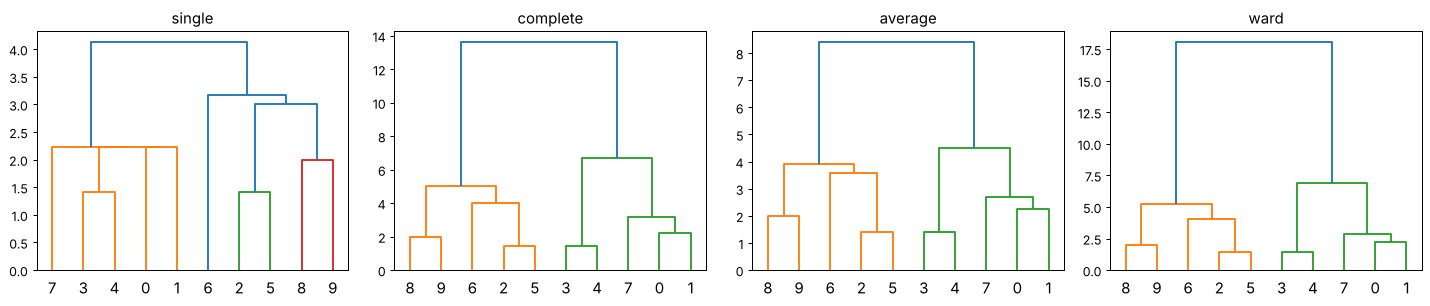

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, method in zip(axes, ["single", "complete", "average", "ward"]):
    dendrogram(linkage(points, method=method), ax=ax)
    ax.set_title(method)
fig.tight_layout()

## 4. Choosing the number of clusters
Cut the tree into *k* clusters with `fcluster` and score each cut with the silhouette coefficient (higher = tighter, better-separated clusters).

k=2: silhouette=0.564  labels=[2 2 1 2 2 1 1 2 1 1]
k=3: silhouette=0.499  labels=[3 3 1 2 2 1 1 3 1 1]
k=4: silhouette=0.418  labels=[4 4 2 3 3 2 2 4 1 1]
k=5: silhouette=0.442  labels=[5 5 2 4 4 2 3 5 1 1]


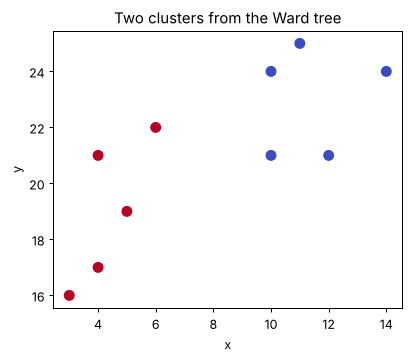

In [5]:
for k in range(2, 6):
    labels = fcluster(Z, t=k, criterion="maxclust")
    print(f"k={k}: silhouette={silhouette_score(points, labels):.3f}  labels={labels}")

labels = fcluster(Z, t=2, criterion="maxclust")
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(x, y, c=labels, cmap="coolwarm", s=60)
ax.set(title="Two clusters from the Ward tree", xlabel="x", ylabel="y")

## 5. Real data: Iris
150 flowers, 4 measurements, 3 species. We cluster **without** the labels, then check how well the clusters recover the species with the Adjusted Rand Index (1 = perfect, 0 = random). Features are standardized first because they have different scales.

  single: ARI=0.558  silhouette=0.505
complete: ARI=0.573  silhouette=0.450
 average: ARI=0.562  silhouette=0.480
    ward: ARI=0.615  silhouette=0.447


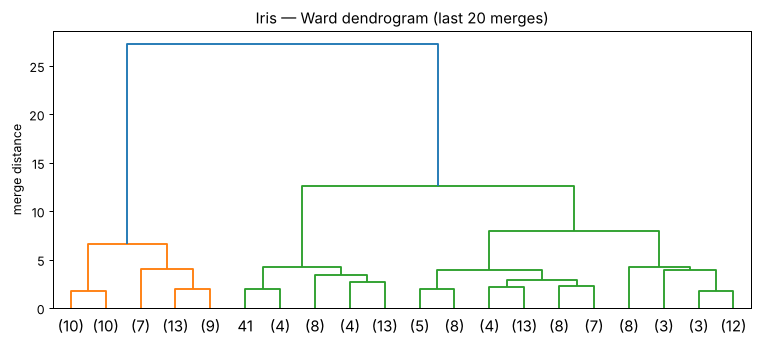

In [6]:
iris = load_iris()
X = StandardScaler().fit_transform(iris.data)
Z_iris = linkage(X, method="ward")

fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(Z_iris, truncate_mode="lastp", p=20, ax=ax)
ax.set(title="Iris — Ward dendrogram (last 20 merges)", ylabel="merge distance")

for method in ["single", "complete", "average", "ward"]:
    pred = fcluster(linkage(X, method=method), t=3, criterion="maxclust")
    ari = adjusted_rand_score(iris.target, pred)
    print(f"{method:>8}: ARI={ari:.3f}  silhouette={silhouette_score(X, pred):.3f}")

## Takeaways

- Ward linkage gives compact, balanced clusters and recovers the Iris species best here; single linkage tends to "chain" points together.
- The dendrogram shows the whole hierarchy, so you can choose *k* after clustering — look for the largest vertical gap, and confirm with a metric such as the silhouette score.
- Hierarchical clustering costs O(n²) memory, so for large datasets use k-means or mini-batch methods instead.